# 03 Stochastic wind model

Hourly site wind jointly with the national wind capacity factor. Method (see
`src/prs/wind.py` for details):

1. Weibull marginal per calendar month, transformed to a standard normal.
2. Remove the (month, hour) mean and sd: the diurnal and seasonal cycle.
3. A bivariate VAR(24) for hour-to-day weather, with correlated innovations
   linking site and national wind (a Gaussian copula).
4. Monthly "weather regime" shocks, so monthly totals vary as much as in
   35 years of ERA5.

Below, each step is checked against the data.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # make src/prs importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prs.plotting import fig, use_style, label_end, BLUE, ORANGE, AQUA, GREY
use_style()
pd.set_option("display.precision", 3)

In [2]:
from scipy import stats
from prs.pipeline import load_models, ERA5_METHOD, FIT_YEARS
from prs.data import load_era5_site
m = load_models()
wind = m["wind"]
site = load_era5_site(ERA5_METHOD, *FIT_YEARS)
pd.DataFrame({"weibull_k": wind.weibull_k, "weibull_c": wind.weibull_c}, index=range(1, 13)).T.round(2)

,1,2,3,4,5,6,7,8,9,10,11,12
weibull_k,2.29,2.34,2.27,2.24,2.19,2.17,2.28,2.30,2.30,2.44,2.37,2.35
weibull_c,9.12,8.93,8.22,7.27,6.97,6.51,6.41,6.64,7.14,8.26,8.47,9.19


Shape k ~2.2-2.4 all year, scale c from ~9.2 m/s in winter to ~6.4 m/s in
summer. k ~ 2 is the textbook value for mid-latitude wind.

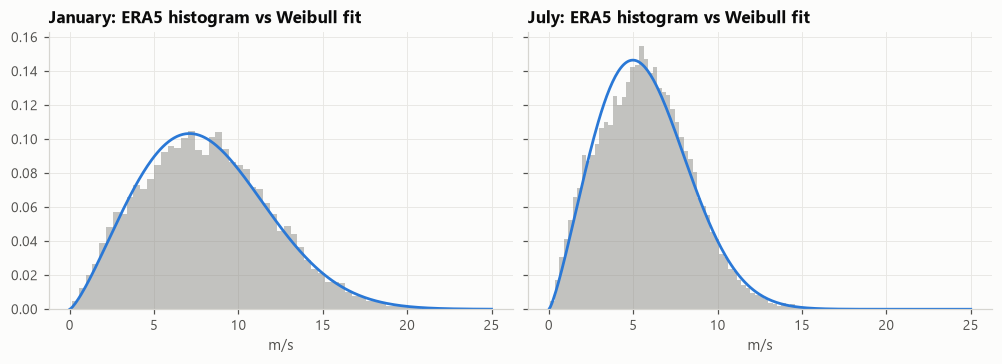

In [3]:
f, axes = fig(1, 2, figsize=(9, 3.2), sharey=True)
for ax, mon, name in zip(axes, [1, 7], ["January", "July"]):
    x = site[site.index.month == mon]
    ax.hist(x, bins=60, density=True, color=GREY, alpha=0.5, lw=0)
    v = np.linspace(0, 25, 300)
    ax.plot(v, stats.weibull_min.pdf(v, wind.weibull_k[mon-1], scale=wind.weibull_c[mon-1]), color=BLUE)
    ax.set_title(f"{name}: ERA5 histogram vs Weibull fit"); ax.set_xlabel("m/s")

Text(0.0, 1.0, 'Hourly wind autocorrelation: daily wiggle and multi-day decay')

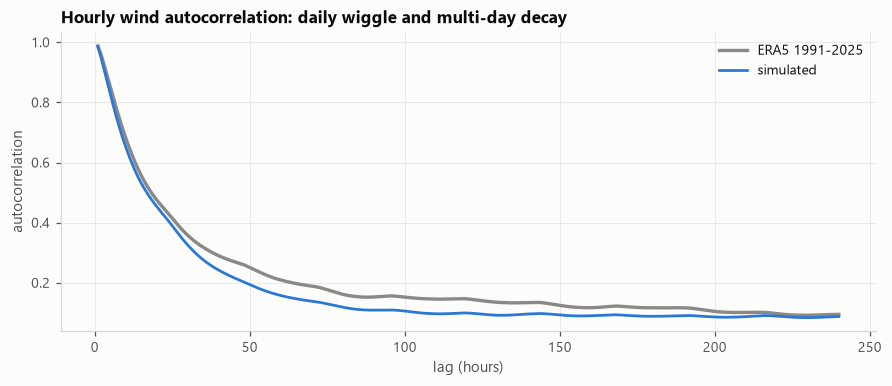

In [4]:
idx = pd.date_range("2027-01-01", periods=8760 * 10, freq="h", tz="UTC")
ws_sim, cf_sim = wind.simulate(idx, 40, seed=1)

def acf(x, lags):
    x = x - x.mean(); v = (x * x).sum()
    return np.array([(x[:-l] * x[l:]).sum() / v for l in lags])

lags = np.arange(1, 241)
a_hist = acf(site.values, lags)
a_sim = np.mean([acf(w, lags) for w in ws_sim[:10]], axis=0)
f, ax = fig(figsize=(8, 3.4))
ax.plot(lags, a_hist, color=GREY, lw=2.2, label="ERA5 1991-2025")
ax.plot(lags, a_sim, color=BLUE, label="simulated")
ax.legend()
ax.set_xlabel("lag (hours)"); ax.set_ylabel("autocorrelation")
ax.set_title("Hourly wind autocorrelation: daily wiggle and multi-day decay")

The VAR(24) reproduces the first day closely (the 24 h lag is where a
shorter VAR fell short). Beyond ~3 days the simulation decorrelates a little faster than reality.
Rather than adding many more lags, the slow part is handled by the monthly
shock below, which targets exactly what the contract settles on.

monthly shock sd: 0.175  annual shock sd: 0.0  site-national shock corr: 0.7


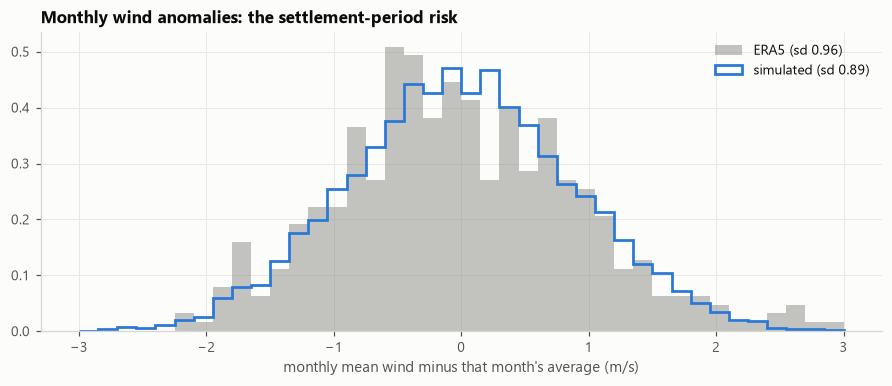

In [5]:
def monthly_anoms(s):
    mm = s.resample("MS").mean()
    return mm - mm.groupby(mm.index.month).transform("mean")

hist_m = monthly_anoms(site)
sim_m = np.concatenate([monthly_anoms(pd.Series(w, idx)).values for w in ws_sim])
f, ax = fig(figsize=(8, 3.4))
bins = np.linspace(-3, 3, 41)
ax.hist(hist_m, bins=bins, density=True, color=GREY, alpha=0.5, lw=0, label=f"ERA5 (sd {hist_m.std():.2f})")
ax.hist(sim_m, bins=bins, density=True, histtype="step", color=BLUE, lw=1.8, label=f"simulated (sd {sim_m.std():.2f})")
ax.set_xlabel("monthly mean wind minus that month's average (m/s)")
ax.set_title("Monthly wind anomalies: the settlement-period risk")
ax.legend()
print("monthly shock sd:", round(wind.sigma_month, 3), " annual shock sd:", round(wind.sigma_year, 3),
      " site-national shock corr:", round(wind.rho_shock, 2))

Without the monthly shock, the VAR alone gave monthly anomalies about 20%
too narrow. With it the spread matches. Annual means then also match (the
annual shock is estimated at ~0: twelve independent monthly shocks already
supply the year-to-year variation seen in ERA5).

## Site vs national wind

Text(0, 0.5, 'national wind capacity factor')

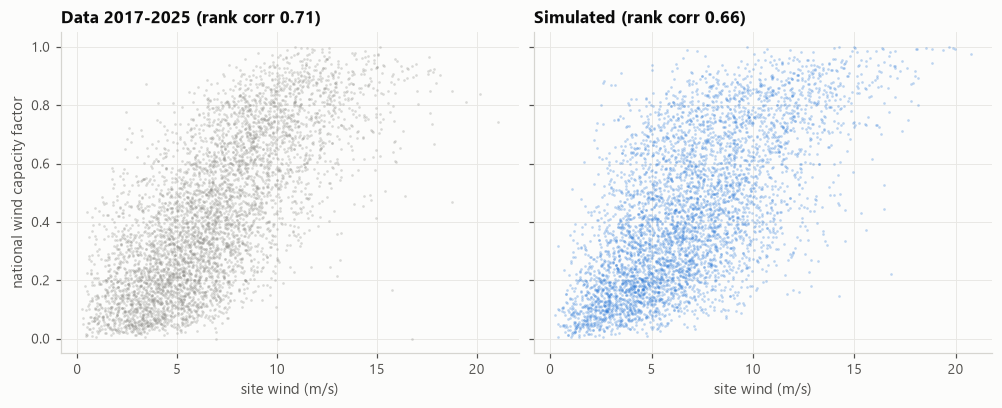

In [6]:
panel = m["panel"].dropna(subset=["ws100", "national_cf"])
hist_corr = stats.spearmanr(panel["ws100"], panel["national_cf"])[0]
sim_corr = stats.spearmanr(ws_sim[:5].ravel(), cf_sim[:5].ravel())[0]
f, axes = fig(1, 2, figsize=(9, 3.6), sharey=True)
s = panel.sample(5000, random_state=1)
axes[0].scatter(s["ws100"], s["national_cf"], s=3, color=GREY, alpha=0.3, lw=0)
axes[0].set_title(f"Data 2017-2025 (rank corr {hist_corr:.2f})")
k = np.random.default_rng(0).choice(ws_sim[0].size, 5000, replace=False)
axes[1].scatter(ws_sim[0][k], cf_sim[0][k], s=3, color=BLUE, alpha=0.3, lw=0)
axes[1].set_title(f"Simulated (rank corr {sim_corr:.2f})")
for ax in axes: ax.set_xlabel("site wind (m/s)")
axes[0].set_ylabel("national wind capacity factor")

The joint behaviour is reproduced: when Pen y Cymoedd is windy, GB
usually is too, but not always (Wales can be windy while Scotland is calm and
vice versa). This imperfect correlation drives cannibalisation risk: the site
produces most when the national fleet does and prices are low.

## Calibrating the "still winter" stress

Text(0.0, 1.0, 'Dec-Feb wind anomaly by winter; calmest: 1964 (-0.46)')

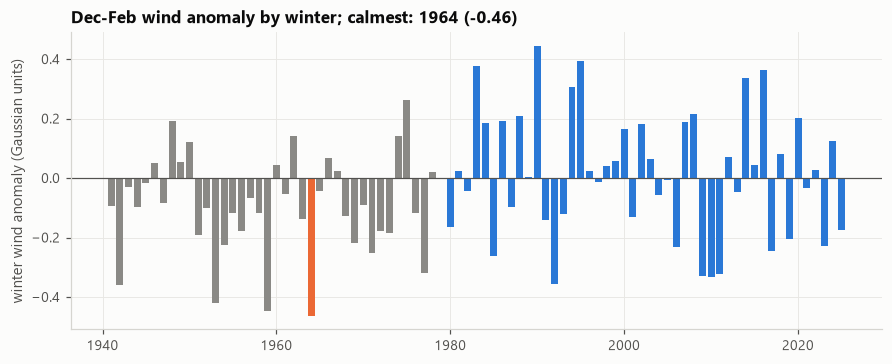

In [7]:
from prs.pipeline import calmest_winter_shift
shift, worst, winters = calmest_winter_shift(wind)
f, ax = fig(figsize=(8, 3.2))
colors = [ORANGE if y == worst else (GREY if y < 1979 else BLUE) for y in winters.index]
ax.bar(winters.index, winters.values, color=colors, width=0.8)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_ylabel("winter wind anomaly (Gaussian units)")
ax.set_title(f"Dec-Feb wind anomaly by winter; calmest: {worst} ({shift:.2f})")

The calmest winter in the 85-year record (1963/64) sits ~0.46 standard
units below normal over three months. That shift, applied to the first
winter of the contract, is the "still winter" stress in notebook 05.